# Data checks and base rates

**Name:** Raaj Banga

Checks the processed table and produces the numbers for the dataset section of the report.

## Part 1: Setup

### Block 1: Imports and paths

In [1]:
# python 3.14.10, pandas 2.3.3, numpy 2.5.4, scikit-learn 1.9.1, scipy 1.18.1, matplotlib 3.11.2
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Find the project folder whether this runs from notebooks/ or the project root
ROOT = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
from config import CRASHES, PROCESSED, SEED
from helpers import (CRASH_COLORS, CRASH_LABELS, CRASH_SHORT, load_firms, save_figure, set_style)

set_style()

### Block 2: Load the data

In [2]:
# One row per firm per crash, from 07_build_features.py
firms = load_firms()
print(firms.shape)
print(firms["crash"].value_counts().to_string())

(10513, 70)
crash
tariff_2025    3698
rates_2022     3599
covid_2020     3216


## Part 2: Dataset

### Block 3: Rows per crash and price source

Yahoo vs Tiingo rows per crash, for the dataset section.

In [3]:
# Rows per crash by price source (Yahoo for listed firms, Tiingo for firms that left)
sources = pd.crosstab(firms["price_source"], firms["crash"], margins=True, margins_name="All")
sources = sources[list(CRASHES) + ["All"]].rename(columns=CRASH_SHORT)
print(sources.to_string())
print(f"\nFirms: {firms['cik'].nunique():,}; ADR rows: {firms['is_adr'].sum()}")

crash         2020  2022  2025    All
price_source                         
tiingo         758   666   321   1745
yahoo         2458  2933  3377   8768
All           3216  3599  3698  10513

Firms: 4,657; ADR rows: 11


### Block 4: Filter counts

Table from `data/interim/filter_counts.csv`, for the dataset section.

In [4]:
# From SEC filers to the final table: universe filters (03), then label and feature steps (06, 07)
universe = pd.read_csv(ROOT / "data/interim/filter_counts.csv", index_col="step")
labels = pd.read_csv(ROOT / "data/interim/label_counts.csv", index_col="step")
final = firms.groupby("crash").size().to_frame("Not a business development company (07)").T
steps = pd.concat([universe, labels, final])[list(CRASHES)].rename(columns=CRASH_SHORT)
print(steps.to_string())

                                                             2020   2022   2025
All companies                                               20547  20547  20547
Has a 10-K filed before the peak                            10631  11495  13264
Latest 10-K is recent                                        5675   5745   5749
Not a SPAC (SIC 6770)                                        5618   5582   5580
Not a SPAC (most assets in trust)                            5581   5455   5511
Not a SPAC (name at peak)                                    5574   5440   5500
Not a fund or asset-backed issuer                            5512   5382   5432
Public float above zero, or a common ticker                  5095   5077   5119
Matched rows with a checked price                            4031   4282   4618
Common stock only                                            4026   4276   4605
Has 20+ closes in the 30 days before the peak                4008   4272   4568
Pre-crash price at least $1             

### Block 5: Feature coverage

Share of firms each feature covers, per crash, and the missing flags.

In [5]:
# Share of rows with each feature, per crash (also in data/interim/feature_coverage.csv)
FEATURES = ["current_ratio", "cash_to_assets", "debt_to_assets", "liabilities_to_assets",
            "interest_coverage", "net_margin", "operating_margin", "return_on_assets",
            "ocf_to_assets", "revenue_growth", "asset_growth", "log_assets",
            "log_market_value", "volatility_12m", "momentum_12_1", "beta"]
coverage = firms.groupby("crash")[FEATURES].apply(lambda g: g.notna().mean()).T
print((coverage[list(CRASHES)].rename(columns=CRASH_SHORT) * 100).round(1).to_string())

# Gaps in non-financial firms only: current ratio and interest coverage are left
# missing for financial firms on purpose
nonfin = firms[firms["is_financial"] == 0]
print("\nNon-financial firms, current ratio and interest coverage:")
print((nonfin.groupby("crash")[["current_ratio", "interest_coverage"]].apply(lambda g: g.notna().mean())
       .T[list(CRASHES)].rename(columns=CRASH_SHORT) * 100).round(1).to_string())

flags = [c for c in firms.columns if c.endswith("_missing")]
n_missing = firms[flags].sum(axis=1)
print(f"\n{len(flags)} missing flags. Rows with every feature: {(n_missing == 0).mean():.1%}; "
      f"median features missing per row: {n_missing.median():.0f}")

crash                   2020   2022   2025
current_ratio           75.3   76.6   76.7
cash_to_assets          97.7   97.4   98.3
debt_to_assets          60.2   59.4   56.9
liabilities_to_assets   99.7   99.6   99.7
interest_coverage       43.6   43.1   40.5
net_margin              73.1   72.6   74.6
operating_margin        67.4   65.8   67.6
return_on_assets        92.8   93.2   94.4
ocf_to_assets           94.9   97.7   98.1
revenue_growth          77.2   76.2   78.3
asset_growth            99.3   97.9   98.9
log_assets             100.0  100.0  100.0
log_market_value        91.1   90.7   87.8
volatility_12m          99.8   99.7   99.8
momentum_12_1           99.4   98.8   99.2
beta                    99.8   99.7   99.8

Non-financial firms, current ratio and interest coverage:
crash              2020  2022  2025
current_ratio      97.9  98.2  98.1
interest_coverage  56.7  55.2  51.8

16 missing flags. Rows with every feature: 20.6%; median features missing per row: 2


### Block 6: Firm overlap between crashes

How many firms appear in two or three crashes. Notebook 02 must keep the same firm from inflating results.

In [6]:
# How many crashes each firm appears in. Notebook 02 groups folds by cik for this reason.
per_firm = firms.groupby("cik")["crash"].nunique()
overlap = per_firm.value_counts().sort_index().rename_axis("crashes").to_frame("firms")
overlap["rows"] = overlap["firms"] * overlap.index
overlap["share of rows"] = (overlap["rows"] / len(firms)).round(3)
print(overlap.to_string())

# Pairs of crashes that share firms
sets = {c: set(firms.loc[firms["crash"] == c, "cik"]) for c in CRASHES}
for a, b in [("covid_2020", "rates_2022"), ("rates_2022", "tariff_2025"), ("covid_2020", "tariff_2025")]:
    shared = len(sets[a] & sets[b])
    print(f"{CRASH_SHORT[a]} and {CRASH_SHORT[b]}: {shared:,} firms in both "
          f"({shared / len(sets[b]):.0%} of {CRASH_SHORT[b]})")

         firms  rows  share of rows
crashes                            
1         1293  1293          0.123
2          872  1744          0.166
3         2492  7476          0.711
2020 and 2022: 2,908 firms in both (81% of 2022)
2022 and 2025: 2,922 firms in both (79% of 2025)
2020 and 2025: 2,518 firms in both (68% of 2025)


## Part 3: Labels

### Block 7: Base rates per crash and label

Primary label (back to pre-crash price within 12 months) and second label (beats the market).

       rows  recovered_12m  beat_market  recovered_18m  spy_return
crash                                                             
2020   3216          0.756        0.477          0.826       0.177
2022   3599          0.428        0.320          0.489      -0.067
2025   3698          0.695        0.388          0.756       0.119


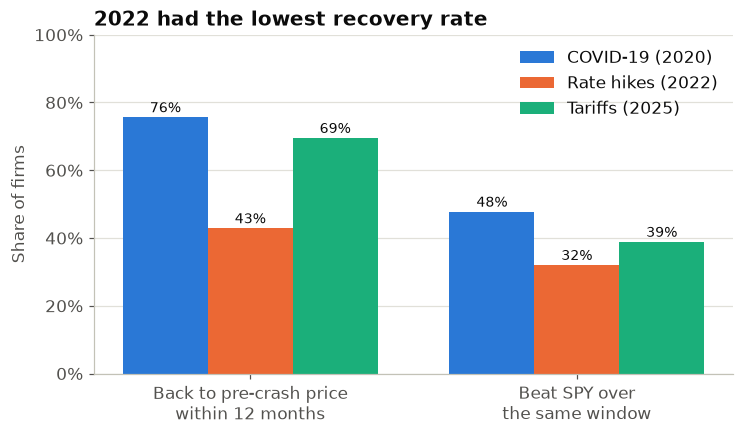

In [7]:
# Base rates per crash and label, with the market's own return over the same window
rates = firms.groupby("crash").agg(
    rows=("cik", "size"),
    recovered_12m=("recovered_12m", "mean"),
    beat_market=("beat_market", "mean"),
    recovered_18m=("recovered_event", "mean"),
    spy_return=("spy_return", "first"),
).loc[list(CRASHES)]
print(rates.rename(index=CRASH_SHORT).round(3).to_string())

fig, ax = plt.subplots(figsize=(7.5, 4))
names = {"recovered_12m": "Back to pre-crash price\nwithin 12 months", "beat_market": "Beat SPY over\nthe same window"}
width = 0.26
for j, crash in enumerate(CRASHES):
    x = np.arange(len(names)) + (j - 1) * width
    vals = rates.loc[crash, list(names)].values
    bars = ax.bar(x, vals, width, color=CRASH_COLORS[crash], label=CRASH_LABELS[crash])
    for xi, v in zip(x, vals):
        ax.text(xi, v + 0.015, f"{v:.0%}", ha="center", fontsize=9)
ax.set_xticks(np.arange(len(names)), list(names.values()))
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_ylabel("Share of firms")
ax.set_title("2022 had the lowest recovery rate")
ax.legend(loc="upper right")
save_figure(fig, "base_rates")
plt.show()

### Block 8: Drawdown by crash

Distribution of drawdown from the pre-crash price, one panel per crash.

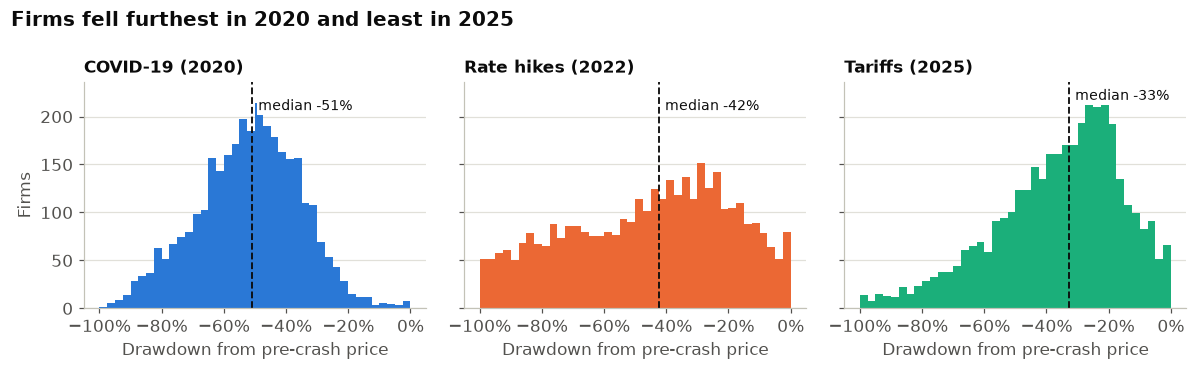

        count   mean    std    min    10%    50%    90%  max
crash                                                       
2020   3216.0 -0.518  0.166 -0.985 -0.747 -0.509 -0.314  0.0
2022   3599.0 -0.457  0.262 -1.000 -0.844 -0.424 -0.124  0.0
2025   3698.0 -0.360  0.203 -0.999 -0.649 -0.328 -0.120  0.0


In [8]:
# Drawdown: lowest close from the peak through 3 months after the trough, vs the pre-crash price
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
bins = np.linspace(-1, 0, 41)
for ax, crash in zip(axes, CRASHES):
    dd = firms.loc[firms["crash"] == crash, "drawdown"]
    ax.hist(dd, bins=bins, color=CRASH_COLORS[crash])
    ax.axvline(dd.median(), color="#0b0b0b", linewidth=1.2, linestyle="--")
    ax.text(dd.median() + 0.02, ax.get_ylim()[1] * 0.92, f"median {dd.median():.0%}", fontsize=9,
            bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set_title(CRASH_LABELS[crash], fontsize=11)
    ax.set_xlabel("Drawdown from pre-crash price")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
axes[0].set_ylabel("Firms")
fig.suptitle("Firms fell furthest in 2020 and least in 2025", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_figure(fig, "drawdowns")
plt.show()

print(firms.groupby("crash")["drawdown"].describe(percentiles=[0.1, 0.5, 0.9])
      .loc[list(CRASHES)].rename(index=CRASH_SHORT).round(3).to_string())

### Block 9: Exit status by crash

From Form 25, Form 15, and 8-K filings between the peak and 18 months after the trough (rules in `06_build_labels.py`, Section 6): `failed` (bankruptcy, then delisted), `acquired`, `delisted_other`, or `none`.

In [9]:
exits = pd.crosstab(firms["exit_status"], firms["crash"], margins=True, margins_name="All")
exits = exits.loc[["none", "acquired", "delisted_other", "failed", "All"], list(CRASHES) + ["All"]]
print(exits.rename(columns=CRASH_SHORT).to_string())

print("\nShare recovered within 12 months, by exit status:")
print(firms.pivot_table(index="exit_status", columns="crash", values="recovered_12m", aggfunc="mean")
      .loc[["none", "acquired", "delisted_other", "failed"], list(CRASHES)]
      .rename(columns=CRASH_SHORT).round(3).to_string())

crash           2020  2022  2025    All
exit_status                            
none            3042  3339  3469   9850
acquired         139   197   197    533
delisted_other    12    14    11     37
failed            23    49    21     93
All             3216  3599  3698  10513

Share recovered within 12 months, by exit status:
crash            2020   2022   2025
exit_status                        
none            0.768  0.438  0.701
acquired        0.655  0.371  0.640
delisted_other  0.333  0.214  0.727
failed          0.087  0.041  0.143


## Part 4: Crash context

Macro series describe each crash. They aren't firm features, since every firm in a crash gets the same value.

### Block 10: S&P 500, VIX, and 10-year yield around each crash

From `data/raw/fred`. `SP500` is price-only, so compare it with price-only firm returns.

/var/folders/9q/7lqdq_r95_x38vhxxf5hhmtw0000gn/T/ipykernel_1584/2370821117.py:13: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  w = s[(s.index >= peak - pd.Timedelta(days=60)) & (s.index <= end)]
/var/folders/9q/7lqdq_r95_x38vhxxf5hhmtw0000gn/T/ipykernel_1584/2370821117.py:13: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  w = s[(s.index >= peak - pd.Timedelta(days=60)) & (s.index <= end)]
/var/folders/9q/7lqdq_r95_x38vhxxf5hhmtw0000gn/T/ipykernel_1584/2370821117.py:13: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please u

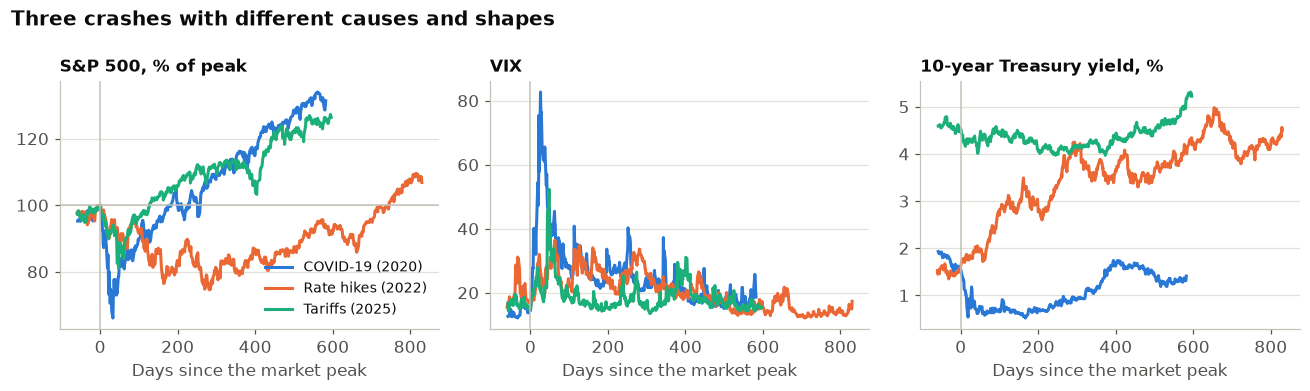

                       2020     2022    2025
days peak to trough  33.000  282.000  48.000
S&P 500 drop         -0.339   -0.254  -0.189
VIX at peak          14.380   16.600  15.270
VIX high             82.690   36.450  52.330
10y at peak           1.560    1.630   4.530
10y at trough         0.760    3.910   4.260


In [10]:
# Each series from 60 days before the peak to 18 months after the trough, by days since the peak
fred = {name: pd.read_csv(ROOT / f"data/raw/fred/{name}.csv", parse_dates=["observation_date"],
                          index_col="observation_date")[name].dropna()
        for name in ["SP500", "VIXCLS", "DGS10"]}
titles = {"SP500": "S&P 500, % of peak", "VIXCLS": "VIX", "DGS10": "10-year Treasury yield, %"}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
context = {}
for crash, c in CRASHES.items():
    peak, trough = pd.Timestamp(c["peak"]), pd.Timestamp(c["trough"])
    end = trough + pd.DateOffset(months=18)
    for ax, (name, s) in zip(axes, fred.items()):
        w = s[(s.index >= peak - pd.Timedelta(days=60)) & (s.index <= end)]
        y = w / s[s.index <= peak].iloc[-1] * 100 if name == "SP500" else w
        ax.plot((w.index - peak).days, y, color=CRASH_COLORS[crash], label=CRASH_LABELS[crash])
    vix = fred["VIXCLS"]
    context[CRASH_SHORT[crash]] = {
        "days peak to trough": (trough - peak).days,
        "S&P 500 drop": fred["SP500"][trough] / fred["SP500"][peak] - 1,
        "VIX at peak": vix[vix.index <= peak].iloc[-1],
        "VIX high": vix[(vix.index >= peak) & (vix.index <= trough)].max(),
        "10y at peak": fred["DGS10"][fred["DGS10"].index <= peak].iloc[-1],
        "10y at trough": fred["DGS10"][fred["DGS10"].index <= trough].iloc[-1],
    }
for ax, name in zip(axes, fred):
    ax.set_title(titles[name], fontsize=11)
    ax.set_xlabel("Days since the market peak")
    ax.axvline(0, color="#c3c2b7", linewidth=1)
axes[0].axhline(100, color="#c3c2b7", linewidth=1)
axes[0].legend(loc="lower right", fontsize=9)
fig.suptitle("Three crashes with different causes and shapes", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_figure(fig, "crash_context")
plt.show()

print(pd.DataFrame(context).round(3).to_string())

### Block 11: Recovery by pre-crash volatility

Firms split into thirds by 12-month volatility before the peak, within each crash. Shows why models don't transfer: volatility helps in 2020 and hurts in 2022 and 2025 (notebook 02, Part 5).

          beat_market               recovered_12m              
crash            2020   2022   2025          2020   2022   2025
vol_group                                                      
Low             0.295  0.414  0.432         0.697  0.559  0.800
Middle          0.552  0.366  0.398         0.799  0.462  0.677
High            0.586  0.181  0.336         0.776  0.266  0.610

Rows without volatility (left out): 28


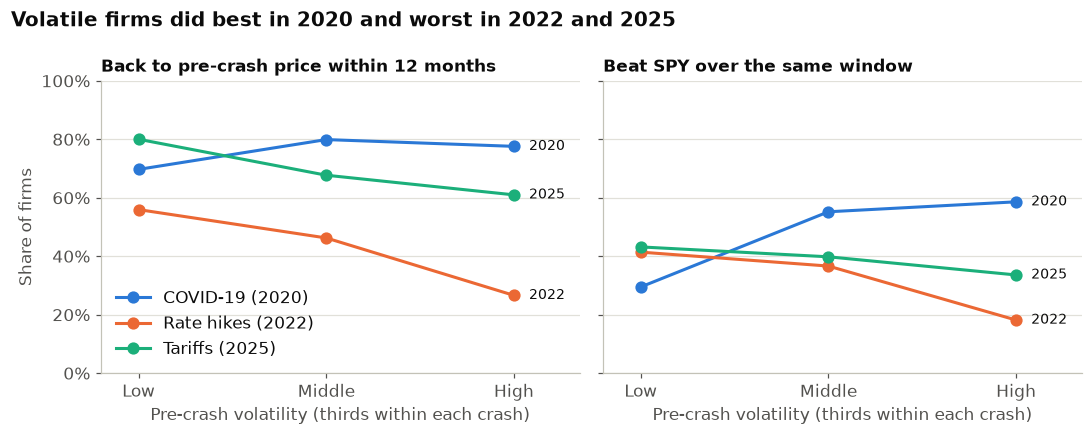

In [11]:
# Volatility thirds within each crash, then the share recovered and beating SPY in each third
firms["vol_group"] = firms.groupby("crash")["volatility_12m"].transform(
    lambda s: pd.qcut(s, 3, labels=["Low", "Middle", "High"]))
flip = firms.pivot_table(index="vol_group", columns="crash", values=["recovered_12m", "beat_market"],
                         aggfunc="mean", observed=True)
print(flip.rename(columns=CRASH_SHORT).round(3).to_string())
print(f"\nRows without volatility (left out): {firms['vol_group'].isna().sum()}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
names = {"recovered_12m": "Back to pre-crash price within 12 months", "beat_market": "Beat SPY over the same window"}
x = np.arange(3)
for ax, (label, title) in zip(axes, names.items()):
    for crash in CRASHES:
        y = flip[(label, crash)].values
        ax.plot(x, y, marker="o", color=CRASH_COLORS[crash], label=CRASH_LABELS[crash])
        ax.text(x[-1] + 0.08, y[-1], CRASH_SHORT[crash], va="center", fontsize=9, color="#0b0b0b")
    ax.set_xticks(x, ["Low", "Middle", "High"])
    ax.set_xlim(-0.2, 2.35)
    ax.set_xlabel("Pre-crash volatility (thirds within each crash)")
    ax.set_title(title, fontsize=11)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Share of firms")
axes[0].legend(loc="lower left")
fig.suptitle("Volatile firms did best in 2020 and worst in 2022 and 2025", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_figure(fig, "volatility_flip")
plt.show()

## Part 5: Notes for the report

**Dataset**
- 10,513 firm-crash rows from 4,657 firms (2026-11-09 rerun, after the audit fixes). 83% come from Yahoo, 17% from Tiingo (mostly firms that left the market). See Blocks 3 and 4.
- Feature coverage is 95% or more for size, price behavior, cash, liabilities, return on assets, and cash flow. The gaps are by design or expected: debt (about 59%), interest coverage (about 42%), margins (about 66 to 75%), and revenue growth (about 77%). See Block 5.
- 71% of rows belong to firms that appear in all three crashes, so notebook 02 must group folds and bootstrap resamples by `cik` (Block 6).

**Labels**
- Recovery within 12 months: 76% (2020), 43% (2022), 70% (2025). Beating SPY: 48%, 32%, 39%. Base rates differ a lot, so report PR-AUC and Brier score alongside AUC (Block 7).
- Median drawdown: -51%, -42%, -33%. 2022 has a wide, flat spread: many firms fell 80% or more (Block 8).
- Exits are rare: 533 acquired, 93 failed, 37 other delistings. Failed firms almost never recover (4 to 14%) (Block 9).

**Crash context** (Block 10)
- 2020: 33 days peak to trough, VIX peaked at 83, and yields fell.
- 2022: 282 days, VIX peaked only at 36, and the 10-year yield rose from 1.6% to 3.9%, a rate shock rather than a panic.
- 2025: 48 days, VIX peaked at 52, and yields stayed high, at about 4.3 to 4.5%.

**Why signals flip** (Block 11)
- Recovery, low to high volatility third: 2020 70% → 78%; 2022 56% → 27%; 2025 80% → 61%.
- Beating SPY: 2020 30% → 59%; 2022 41% → 18%; 2025 43% → 34%.
- In the 2020 liquidity shock, risky firms bounced back most. In the 2022 rate shock and 2025 tariff shock, they recovered least. This is the reversal behind the failed transfer in notebook 02.